使用 Fashion-MNIST 构建两层隐藏层的 MLP；实现训练、验证、测试；在 GPU 上训练；绘制 Loss 和 Accuracy 曲线；保存与加载模型。

In [7]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as Dataset
# 图像数据的处理
import torchvision
import torchvision.transforms as transforms

import matplotlib.pyplot as plt

In [8]:
# 定义数据预处理
transform = transforms.Compose([
    transforms.ToTensor(),  # 转换为张量
    transforms.Normalize((0.5,), (0.5,))  # 标准化
])

In [9]:
data = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
dataset = Dataset.DataLoader(data, batch_size=64, shuffle=True)

100%|██████████| 9.91M/9.91M [00:01<00:00, 7.86MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 333kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 2.54MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 332kB/s]


In [10]:
print(len(data))       # 训练集共有 60000 张图像

image, label = data[0] # 取出第 1 条样本
print(image.shape)     # torch.Size([1, 28, 28])
print(label)           # 5

60000
torch.Size([1, 28, 28])
5


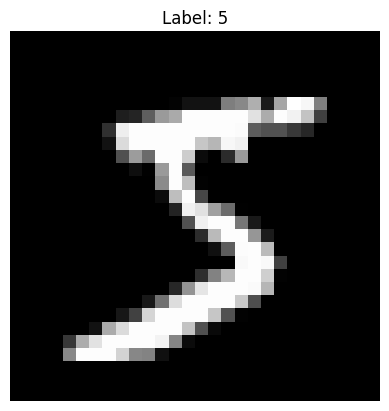

In [11]:
plt.imshow(image[0], cmap="gray")  # 取唯一的灰度通道，形状是 [28, 28]
plt.title(f"Label: {label}")
plt.axis("off")
plt.show()

In [ ]:
print(image[0, :5, :5])      # 经过 transform 的值，范围是 [-1, 1]
print(data.data[0, :5, :5])  # 原始像素值，范围是 [0, 255]
#这两个输出是同一张图左上角的 25 个像素，分别取自预处理前和预处理后。这个区域刚好全是黑色背景，所以原始值全是 0，预处理后全是 -1。

tensor([[-1., -1., -1., -1., -1.],
        [-1., -1., -1., -1., -1.],
        [-1., -1., -1., -1., -1.],
        [-1., -1., -1., -1., -1.],
        [-1., -1., -1., -1., -1.]])
tensor([[0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0]], dtype=torch.uint8)


In [19]:
class SimpleNN(nn.Module):
    def __init__(self):
        super(SimpleNN, self).__init__()
        self.fc1 = nn.Linear(784, 16)
        self.fc2 = nn.Linear(16, 16)
        self.fc3 = nn.Linear(16, 10)
        #self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)
        return x

In [20]:
model = SimpleNN()
criterion = nn.CrossEntropyLoss()  # 多分类交叉熵损失
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [21]:
epochs = 100
model.train()  # 设置模型为训练模式


for epoch in range(epochs):
    for images, labels in dataset:  # 保留第 0 维，合并后面的维度
        #images = images.view(-1, 28*28)  # 固定第1维为 784，自动推算第0维
        images = images.flatten(start_dim=1)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

    if (epoch+1) % 10 == 0:
        print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}')

Epoch [10/100], Loss: 0.1289
Epoch [20/100], Loss: 0.2784
Epoch [30/100], Loss: 0.2308
Epoch [40/100], Loss: 0.1457
Epoch [50/100], Loss: 0.1865
Epoch [60/100], Loss: 0.1050
Epoch [70/100], Loss: 0.1776
Epoch [80/100], Loss: 0.1813
Epoch [90/100], Loss: 0.4015
Epoch [100/100], Loss: 0.0744
